In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

# Download historical daily prices for Apple
ticker = "AAPL"

data = yf.download(
    ticker,
    start="2005-01-01",
    end="2026-11-06",
    auto_adjust=True,
    multi_level_index=False,
    progress=False
)

print("Number of observations:", len(data))
print("First date:", data.index.min())
print("Last date:", data.index.max())

data.head()


Number of observations: 5496
First date: 2005-01-03 00:00:00
Last date: 2026-11-05 00:00:00


,Close,High,Low,Open,Volume
Date,,,,,
2005-01-03,0.946490,0.973708,0.936171,0.968773,691992000
2005-01-04,0.956211,0.979092,0.941705,0.953968,1096810400
2005-01-05,0.964586,0.975802,0.957856,0.963987,680433600
2005-01-06,0.965333,0.970716,0.947088,0.967127,705555200
2005-01-07,1.035621,1.041304,0.968324,0.972063,2227450400


In [9]:

# Step 2: Calculate RSI(14) - Lesson 5, Section 3

period = 14

# Daily price changes
delta = data["Close"].diff()

# Separate positive and negative changes
gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

# Average gains and losses over the last 14 days
avg_gain = gain.rolling(window=period).mean()
avg_loss = loss.rolling(window=period).mean()

# Calculate Relative Strength (RS)
rs = avg_gain / avg_loss

# Calculate RSI
data["RSI"] = 100 - (100 / (1 + rs))

# Handle zero-loss and no-change periods
data.loc[avg_loss == 0, "RSI"] = 100
data.loc[(avg_loss == 0) & (avg_gain == 0), "RSI"] = 50

# Display results
data[["Close", "RSI"]].iloc[14:24]


,Close,RSI
Date,,
2005-01-24,1.058202,70.309931
2005-01-25,1.077494,71.308502
2005-01-26,1.080486,70.755343
2005-01-27,1.086318,71.278304
2005-01-28,1.106357,65.111980
2005-01-31,1.150025,71.717527
2005-02-01,1.159447,94.693199
2005-02-02,1.190851,95.098529
2005-02-03,1.163634,80.363962


In [10]:

# Step 3: Generate RSI trading signals

# 0 = Flat (no position), 1 = Long
position = 0
positions = []

for rsi in data["RSI"]:
    if pd.notna(rsi):
        if rsi < 30:
            position = 1
        elif rsi > 50:
            position = 0

    positions.append(position)

# Signal determined at the end of each day
data["Signal"] = positions

# Apply yesterday's signal to today's return
# This prevents look-ahead bias
data["Position"] = data["Signal"].shift(1).fillna(0)

# Count actual position changes
data["Trade"] = data["Position"].diff().abs()
data["Trade"] = data["Trade"].fillna(data["Position"].abs())

print("Total trades:", int(data["Trade"].sum()))
print("Days invested:", int(data["Position"].sum()))
print("Percentage of days invested:",
      round(data["Position"].mean() * 100, 2), "%")

data[["Close", "RSI", "Signal", "Position", "Trade"]].tail(10)


Total trades: 162
Days invested: 1110
Percentage of days invested: 20.2 %


,Close,RSI,Signal,Position,Trade
Date,,,,,
2026-10-23,347.730011,72.335977,0,0.0,0.0
2026-10-26,343.910004,64.159795,0,0.0,0.0
2026-10-27,347.100006,64.307279,0,0.0,0.0
2026-10-28,343.829987,54.740028,0,0.0,0.0
2026-10-29,348.910004,66.460951,0,0.0,0.0
2026-10-30,344.630005,54.916716,0,0.0,0.0
2026-11-02,338.320007,46.588040,0,0.0,0.0
2026-11-03,331.899994,38.469566,0,0.0,0.0
2026-11-04,349.510010,55.811797,0,0.0,0.0


In [11]:

# Step 4: Calculate net strategy returns

transaction_cost = 0.0005  # 5 basis points per side

# Daily returns of Apple
data["Daily_Return"] = data["Close"].pct_change().fillna(0)

# RSI strategy: gross returns
data["Strategy_Gross"] = (
    data["Position"] * data["Daily_Return"]
)

# Transaction costs
data["Transaction_Cost"] = (
    data["Trade"] * transaction_cost
)

# RSI strategy: net returns
data["Strategy_Net"] = (
    data["Strategy_Gross"] - data["Transaction_Cost"]
)

# Buy-and-hold, including initial purchase cost
data["Buy_Hold_Net"] = data["Daily_Return"].copy()
data.loc[data.index[0], "Buy_Hold_Net"] = -transaction_cost

# Cumulative growth of $1 invested
data["RSI_Equity"] = (
    1 + data["Strategy_Net"]
).cumprod()

data["Buy_Hold_Equity"] = (
    1 + data["Buy_Hold_Net"]
).cumprod()

# Summary of trading costs
print("Total trades:", int(data["Trade"].sum()))
print("Total transaction costs:",
      round(data["Transaction_Cost"].sum() * 100, 2), "%")

print("Final RSI equity:",
      round(data["RSI_Equity"].iloc[-1], 4))

print("Final Buy-and-Hold equity:",
      round(data["Buy_Hold_Equity"].iloc[-1], 4))

data[["Daily_Return", "Position",
      "Transaction_Cost", "Strategy_Net",
      "RSI_Equity", "Buy_Hold_Equity"]].tail()


Total trades: 162
Total transaction costs: 8.1 %
Final RSI equity: 2.9239
Final Buy-and-Hold equity: 363.4457


,Daily_Return,Position,Transaction_Cost,Strategy_Net,RSI_Equity,Buy_Hold_Equity
Date,,,,,,
2026-10-30,-0.012267,0.0,0.0,-0.0,2.923924,363.931448
2026-11-02,-0.018309,0.0,0.0,-0.0,2.923924,357.268051
2026-11-03,-0.018976,0.0,0.0,-0.0,2.923924,350.488477
2026-11-04,0.053058,0.0,0.0,0.0,2.923924,369.084764
2026-11-05,-0.015279,0.0,0.0,-0.0,2.923924,363.445695


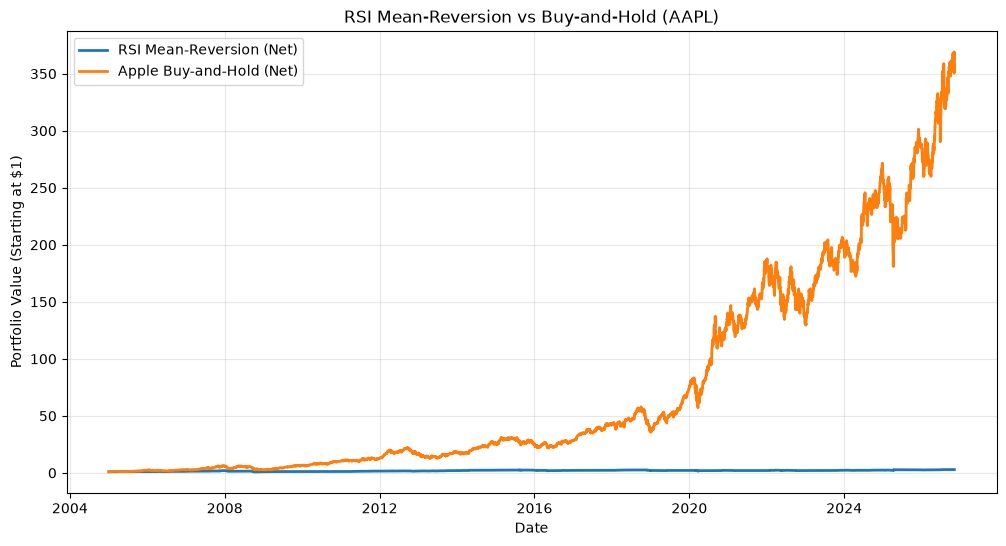

In [12]:

# Step 5: Plot equity curves

plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data["RSI_Equity"],
    label="RSI Mean-Reversion (Net)",
    linewidth=2
)

plt.plot(
    data.index,
    data["Buy_Hold_Equity"],
    label="Apple Buy-and-Hold (Net)",
    linewidth=2
)

plt.title("RSI Mean-Reversion vs Buy-and-Hold (AAPL)")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (Starting at $1)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


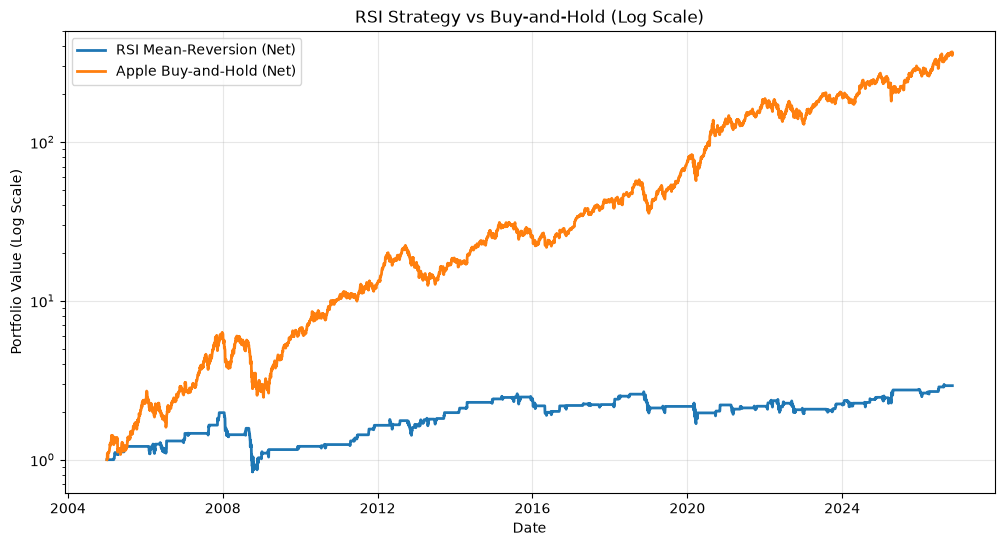

In [13]:

# Equity curves with logarithmic scale

plt.figure(figsize=(12, 6))

plt.plot(
    data.index,
    data["RSI_Equity"],
    label="RSI Mean-Reversion (Net)",
    linewidth=2
)

plt.plot(
    data.index,
    data["Buy_Hold_Equity"],
    label="Apple Buy-and-Hold (Net)",
    linewidth=2
)

plt.yscale("log")

plt.title("RSI Strategy vs Buy-and-Hold (Log Scale)")
plt.xlabel("Date")
plt.ylabel("Portfolio Value (Log Scale)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


In [14]:

# Step 6: Calculate performance metrics

trading_days = 252
risk_free_rate = 0.0

def performance_metrics(returns):

    returns = returns.dropna()
    n = len(returns)

    equity = (1 + returns).cumprod()

    # Annualised compounded return
    annual_return = equity.iloc[-1] ** (trading_days / n) - 1

    # Annualised volatility
    annual_vol = returns.std() * np.sqrt(trading_days)

    # Annualised Sharpe ratio
    annual_mean = returns.mean() * trading_days

    sharpe = (
        (annual_mean - risk_free_rate) / annual_vol
        if annual_vol > 0 else np.nan
    )

    # Maximum drawdown
    running_max = equity.cummax().clip(lower=1)
    drawdown = equity / running_max - 1
    max_drawdown = drawdown.min()

    return {
        "Annualised Return": annual_return,
        "Annualised Volatility": annual_vol,
        "Sharpe Ratio": sharpe,
        "Maximum Drawdown": max_drawdown
    }


# Compare both strategies
results = pd.DataFrame({
    "RSI Strategy": performance_metrics(data["Strategy_Net"]),
    "Buy-and-Hold": performance_metrics(data["Buy_Hold_Net"])
}).T

# Format for presentation
results_formatted = results.copy()

for col in ["Annualised Return",
            "Annualised Volatility",
            "Maximum Drawdown"]:
    results_formatted[col] = results[col].map(
        lambda x: f"{x:.2%}"
    )

results_formatted["Sharpe Ratio"] = (
    results["Sharpe Ratio"].map(lambda x: f"{x:.3f}")
)

results_formatted


,Annualised Return,Annualised Volatility,Sharpe Ratio,Maximum Drawdown
RSI Strategy,5.04%,19.20%,0.352,-57.67%
Buy-and-Hold,31.04%,31.94%,1.006,-60.87%
